In [19]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq

from HATS_functions import xcorr_fft

In [20]:
PathToFiles = "../Audio_Files/HATS/H1/45"
L_sensitivity = 18.0584248155355
R_sensitivity = 16.7419165372849
p_ref = 20e-6

In [21]:
dataL, fs = sf.read(f'{PathToFiles}/L.wav')
pressureL = dataL/(L_sensitivity/1000)
dBL = 20*np.log10(np.abs(pressureL)/p_ref + 1e-12)
print(dBL)

dataR, fs = sf.read(f'{PathToFiles}/R.wav')
pressureR = dataR/(R_sensitivity/1000)
dBR = 20*np.log10(np.abs(pressureR)/p_ref+ 1e-12)
print(dBR)

[30.87812208 30.54400821 30.37200477 ... 15.47745488 16.39260469
 14.45440443]
[36.03789868 36.32585509 36.60457065 ... 21.1324982  21.1324982
 21.65907697]


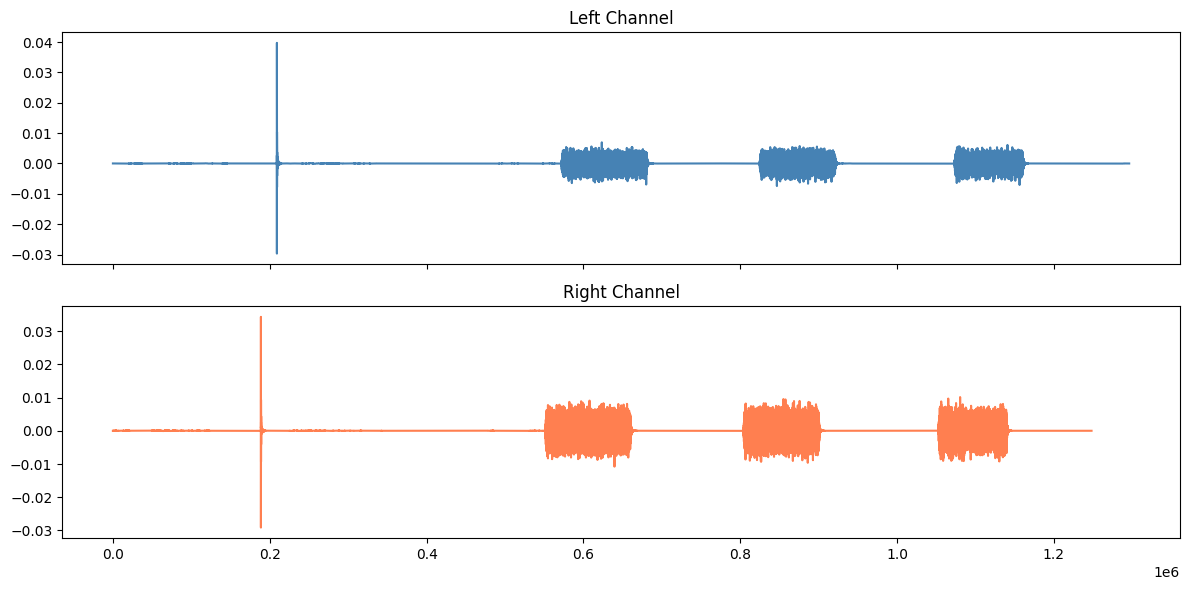

In [22]:
fig, (axL, axR) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axL.plot(dataL, color='steelblue')
axL.set_title('Left Channel')

axR.plot(dataR, color='coral')
axR.set_title('Right Channel')

plt.tight_layout()
plt.show()

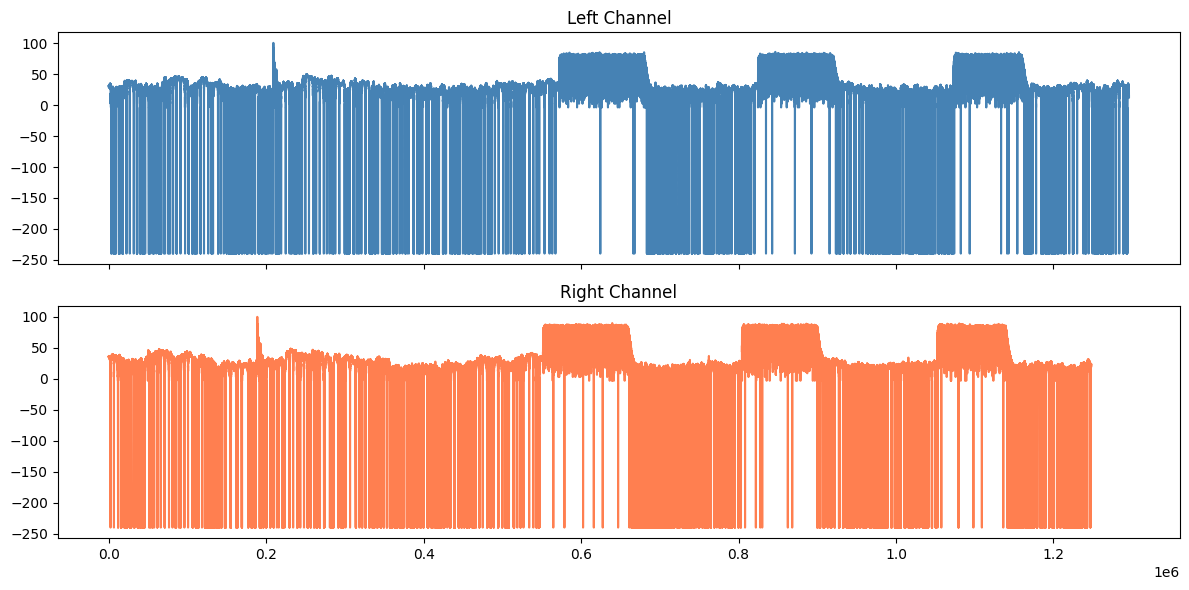

In [23]:
fig, (axL, axR) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axL.plot(dBL, color='steelblue')
axL.set_title('Left Channel')

axR.plot(dBR, color='coral')
axR.set_title('Right Channel')

plt.tight_layout()
plt.show()

In [24]:
L_click_idx = np.argmax(dataL)
R_click_idx = np.argmax(dataR)

L_click_idx, R_click_idx

(np.int64(209134), np.int64(188747))

In [25]:
click_offset = R_click_idx - L_click_idx  # 27609 samples

# Shift the late-starting channel forward
if click_offset > 0:
    # R started later, remove click_offset samples from L
    L_aligned = dataL[click_offset:]
    R_aligned = dataR[:]
else:
    # L started later
    L_aligned = dataL[:]
    R_aligned = dataR[abs(click_offset):]

# both clicks should be at the same position
print(f"L click in aligned signal: {L_click_idx - click_offset if click_offset > 0 else L_click_idx}")
print(f"R click in aligned signal: {R_click_idx if click_offset > 0 else R_click_idx - abs(click_offset)}")

# Trim to noise
aligned_click = L_click_idx - click_offset if click_offset > 0 else L_click_idx
L_Trimmed = L_aligned[aligned_click + fs:]
R_Trimmed = R_aligned[aligned_click + fs:]

min_len = min(len(L_Trimmed), len(R_Trimmed))
L_Trimmed = L_Trimmed[:min_len]
R_Trimmed = R_Trimmed[:min_len]

print(f"L_Trimmed: {len(L_Trimmed)} samples")
print(f"R_Trimmed: {len(R_Trimmed)} samples")

L click in aligned signal: 209134
R click in aligned signal: 168360
L_Trimmed: 970479 samples
R_Trimmed: 970479 samples


In [26]:
d = 0.21 # Microphone Spacing
c = 343.0 # Speed of Sound

correlation = xcorr_fft(L_Trimmed, R_Trimmed)
half = len(correlation) // 2
lags = np.arange(-half, half + 1)[:len(correlation)]

print(f"correlation: {len(correlation)}, lags: {len(lags)}")

max_itd_samples = int((d / c) * fs)
mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
itd_samples = lags[mask][np.argmax(correlation[mask])]
itd_seconds = itd_samples / fs


correlation: 1940956, lags: 1940956


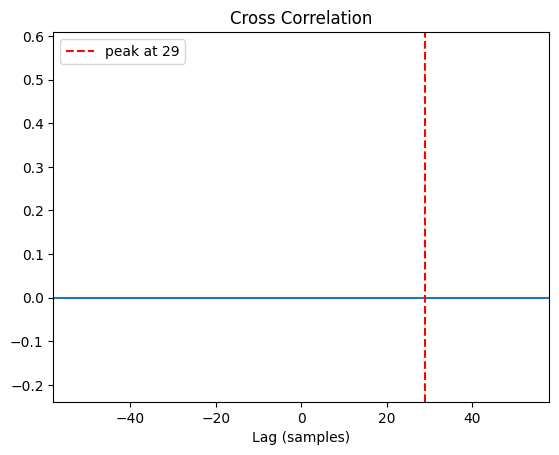

In [27]:
plt.plot(lags, correlation)
plt.axvline(x=itd_samples, color='r', linestyle='--', label=f'peak at {itd_samples}')
plt.xlim(-max_itd_samples*2, max_itd_samples*2)  # zoom in
plt.xlabel('Lag (samples)')
plt.title('Cross Correlation')
plt.legend()
plt.show()

In [28]:
def gcc_phat(L, R):
    n = len(L) + len(R) - 1
    L_fft = np.fft.rfft(L, n=n)
    R_fft = np.fft.rfft(R, n=n)
    cross = L_fft * np.conj(R_fft)
    cross /= (np.abs(cross) + 1e-12)  # PHAT weighting
    result = np.fft.irfft(cross)
    return result[:len(result) if n % 2 != 0 else len(result)]

correlation = gcc_phat(dataL, dataR)
half = len(correlation) // 2
lags = np.arange(-half, half + 1)[:len(correlation)]

max_itd_samples = int((d / c) * fs)
mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
itd_samples = lags[mask][np.argmax(correlation[mask])]
itd_seconds = itd_samples / fs

In [29]:
print(f"Click offset: {R_click_idx - L_click_idx} samples = {(R_click_idx - L_click_idx)/fs*1000:.2f} ms")

Click offset: -20387 samples = -424.73 ms


In [30]:
sin_theta = np.clip((itd_seconds * c) / d, -1, 1)
angle_deg = np.degrees(np.arcsin(sin_theta))

print(f"ITD: {itd_seconds*1000:.3f} ms → {angle_deg:.1f}°")

ITD: 0.562 ms → 66.7°


# Woodsworths

In [31]:
# Woodworth with B&K head radius
r = 0.0875  # metres

def woodworth_itd(angle_deg, r=r, c=343.0):
    theta = np.radians(angle_deg)
    if abs(theta) <= np.pi/2:
        return (r / c) * (np.sin(theta) + theta)
    else:
        return (r / c) * (np.sign(theta) * np.pi - theta + np.sin(theta))

def itd_to_angle(itd_s, r=r, c=343.0):
    from scipy.optimize import brentq
    f = lambda theta: (r/c) * (np.sin(theta) + theta) - itd_s
    return np.degrees(brentq(f, -np.pi/2, np.pi/2))


correlation = gcc_phat(L_Trimmed, R_Trimmed)
half = len(correlation) // 2
lags = np.arange(-half, half + 1)[:len(correlation)]

max_itd_samples = int((r / c) * fs * (np.pi/2 + 1))  # Woodworth max ITD
mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
itd_samples = lags[mask][np.argmax(correlation[mask])]
itd_seconds = itd_samples / fs

angle_deg = itd_to_angle(itd_seconds)
print(f"ITD: {itd_seconds*1000:.3f} ms → {angle_deg:.1f}°")

ITD: 0.146 ms → 16.5°
